# Slot 2: Neural network, model search and validation

This notebook **displays** the results of the pre-registered search ([PROTOCOL.md](PROTOCOL.md)). The search itself runs in `nn_research.py`, because it trains about 850 networks (≈7 min with the LSTMs).

```bash
python notebooks/02_neural_net/nn_research.py --lstm   # writes results/strategies/neural_net/research/
python notebooks/02_neural_net/make_figures.py         # figures + stress table
```

**Rules:**
- Hyper-parameters are chosen on a walk-forward **inside train**: fits on 2005–10/12/14/16, each scored on the following two years, 2011–2018 out of fold.
- Validation (2019–2021) is looked at **once**.
- The test period is never loaded.

The complete record of what was done (deviations, crashed runs, post-hoc decisions) is in [REVIEW_LOG.md](REVIEW_LOG.md).

In [1]:
import json
from pathlib import Path
import pandas as pd
from IPython.display import Image, display
R = Path("../../results/strategies/neural_net/research")
pd.set_option("display.width", 200, "display.max_columns", 30, "display.precision", 3)

## 1. Walk-forward search on train (2011–2018 out of fold; buy & hold = 0.89)

In [2]:
wf = pd.read_csv(R / "walk_forward.csv")
cols = [c for c in ["family", "mode", "lags", "hidden", "threshold", "l2", "turnover_bps", "band",
                    "model", "horizon", "seq_len", "sharpe", "cagr", "max_dd", "exposure", "changes"]
        if c in wf]
wf[cols].sort_values(["family", "sharpe"], ascending=[True, False])

,family,mode,lags,hidden,threshold,l2,turnover_bps,band,model,horizon,seq_len,sharpe,cagr,max_dd,exposure,changes
10,A,direction,20.0,"(32, 16)",0.5,0.010,NaN,0.0,NaN,NaN,NaN,0.908,0.134,-0.154,0.869,348
6,A,direction,10.0,"(32, 16)",0.5,0.010,NaN,0.0,NaN,NaN,NaN,0.864,0.133,-0.213,0.914,255
8,A,direction,20.0,"(8,)",0.5,0.010,NaN,0.0,NaN,NaN,NaN,0.813,0.117,-0.201,0.819,528
0,A,direction,5.0,"(8,)",0.5,0.010,NaN,0.0,NaN,NaN,NaN,0.804,0.123,-0.234,0.936,185
4,A,direction,10.0,"(8,)",0.5,0.010,NaN,0.0,NaN,NaN,NaN,0.753,0.107,-0.214,0.882,314
9,A,direction,20.0,"(8,)",base,0.010,NaN,0.0,NaN,NaN,NaN,0.750,0.086,-0.141,0.570,846
2,A,direction,5.0,"(32, 16)",0.5,0.010,NaN,0.0,NaN,NaN,NaN,0.635,0.099,-0.268,0.961,144
11,A,direction,20.0,"(32, 16)",base,0.010,NaN,0.0,NaN,NaN,NaN,0.517,0.054,-0.157,0.561,738
1,A,direction,5.0,"(8,)",base,0.010,NaN,0.0,NaN,NaN,NaN,0.376,0.042,-0.167,0.652,638
3,A,direction,5.0,"(32, 16)",base,0.010,NaN,0.0,NaN,NaN,NaN,0.204,0.021,-0.199,0.598,707


## 2. Best configuration per family (train only)

In [3]:
best = pd.read_csv(R / "best_per_family.csv")
best[[c for c in cols if c in best]]

,family,mode,lags,hidden,threshold,l2,turnover_bps,band,model,horizon,seq_len,sharpe,cagr,max_dd,exposure,changes
0,A,direction,20.0,"(32, 16)",0.5,0.01,NaN,0.0,NaN,NaN,NaN,0.908,0.134,-0.154,0.869,348
1,B,direction,NaN,16,NaN,NaN,NaN,NaN,NaN,NaN,63.0,0.181,0.017,-0.180,0.391,91
2,C,sharpe,NaN,"(32, 16)",NaN,0.10,25.0,0.1,NaN,NaN,NaN,0.917,0.082,-0.119,0.503,5
3,C-LSTM,sharpe,NaN,16,NaN,NaN,25.0,NaN,NaN,NaN,63.0,0.916,0.084,-0.118,0.529,2011
4,D,NaN,NaN,"(16,)",NaN,NaN,NaN,NaN,mlp,5.0,NaN,0.850,0.135,-0.201,0.969,72
5,D-baseline,NaN,NaN,NaN,NaN,NaN,NaN,NaN,rv20,5.0,NaN,0.911,0.144,-0.180,0.960,36


## 3. Seed dispersion of the two NN picks (walk-forward Sharpe of each seed alone)
Direction models are seed-sensitive, and Sharpe-trained ones are not. The slot trades a 5-seed average.

In [4]:
json.loads((R / "seed_dispersion.json").read_text())

{'A': {'seed_mean': 0.6617750428167992,
  'seed_sd': 0.2009428125727515,
  'seeds': [0.509, 0.971, 0.46, 0.7, 0.669]},
 'C': {'seed_mean': 0.8871657602419744,
  'seed_sd': 0.05144864668461761,
  'seeds': [0.816, 0.881, 0.876, 0.958, 0.906]}}

## 4. Volatility-forecast quality, family D (out of fold, 2011–2018; lower is better)

In [5]:
pd.read_csv(R / "vol_forecast_quality.csv", index_col=0)

,qlike,mse_log
"{""model"": ""har"", ""horizon"": ""5""}",0.481,0.198
"{""model"": ""har"", ""horizon"": ""21""}",0.305,0.115
"{""model"": ""mlp"", ""horizon"": ""5"", ""hidden"": ""(16,)""}",0.486,0.203
"{""model"": ""mlp"", ""horizon"": ""5"", ""hidden"": ""(32, 16)""}",0.475,0.205
"{""model"": ""mlp"", ""horizon"": ""21"", ""hidden"": ""(16,)""}",0.282,0.120
"{""model"": ""mlp"", ""horizon"": ""21"", ""hidden"": ""(32, 16)""}",0.284,0.119
"{""model"": ""rv20"", ""horizon"": ""5""}",0.598,0.279
"{""model"": ""ewma"", ""horizon"": ""5""}",0.497,0.266
"{""model"": ""rv20"", ""horizon"": ""21""}",0.468,0.180
"{""model"": ""ewma"", ""horizon"": ""21""}",0.349,0.145


## 5. Validation, looked at once
Decision ladder (PROTOCOL.md):
- **v1 = A.**
- **v2 = the best of C and D on train = C** (0.917 vs 0.850). C beats v1 on train (0.917 vs 0.908) and on validation (1.51 vs 1.09, with a smaller drawdown), so it is **adopted**.
- **v3 = an LSTM.** C-LSTM (0.916) does not beat v2 on train, so it is **not adopted**.

In [6]:
pd.read_csv(R / "validation_once.csv", index_col=0)

,train_sharpe,val_sharpe,val_ci,val_cagr,val_vol,val_max_dd,val_exposure,val_changes,train_max_dd,val_auc,val_share_long
buy_and_hold,0.564,1.385,"[0.29, 2.68]",0.379,0.249,-0.286,1.000,0,-0.534,NaN,NaN
A,1.639,1.089,"[-0.22, 2.68]",0.239,0.210,-0.332,0.793,241,-0.180,0.504,0.793
B,0.578,0.866,"[-0.18, 2.08]",0.111,0.120,-0.132,0.613,141,-0.184,NaN,NaN
C,0.772,1.508,"[0.39, 2.76]",0.086,0.050,-0.059,0.227,8,-0.109,NaN,NaN
C-LSTM,0.962,1.448,"[0.3, 2.66]",0.148,0.093,-0.100,0.460,757,-0.139,NaN,NaN
D,0.643,1.517,"[0.38, 2.62]",0.316,0.187,-0.189,0.934,84,-0.430,NaN,NaN
D-baseline,0.711,1.472,"[0.33, 2.64]",0.289,0.178,-0.190,0.881,39,-0.383,NaN,NaN


## 6. Post-hoc addendum: v2b (volatility rescaling)
The Sharpe loss doesn't change when every position is multiplied by the same constant, so v2's exposure level (≈25%) is arbitrary. v2b rescales the output to QQQ's train volatility.

The rule was written before running v2b: adopt if its walk-forward Sharpe ≥ v2's − 0.05. Its validation result is post-hoc.

In [7]:
pd.read_csv(R / "v2b_scaled_posthoc.csv", index_col=0).T

,C_v2b_scaled (post-hoc)
config,"{""mode"": ""sharpe"", ""hidden"": ""(32, 16)"", ""l2"":..."
wf_sharpe,0.885
wf_exposure,0.971
wf_changes,9
wf_max_dd,-0.222
adopted_by_rule,True
scale_k,3.844
train_sharpe,0.723
train_cagr,0.121
train_max_dd,-0.392


## 7. Stress episodes (* = inside train, in-sample for the networks)

In [8]:
pd.read_csv(R / "stress_episodes.csv", index_col=0).map(lambda v: f"{v:+.1%}")

,v1 direction,v2 Sharpe,"v2b Sharpe, rescaled",Slot 1 MA v3,Buy & hold
Financial crisis (31 Oct 2007 – 9 Mar 2009)*,+36.4%,-10.3%,-38.4%,-25.7%,-52.3%
Q4 2018 sell-off (1 Oct – 24 Dec 2018)*,-0.3%,-4.7%,-18.9%,-9.2%,-22.5%
COVID crash (20 Feb – 23 Mar 2020),-33.1%,-5.7%,-15.8%,-18.2%,-27.9%
COVID crash and rebound (20 Feb – 31 Dec 2020),+10.7%,+5.0%,+7.6%,+18.0%,+33.1%


## 8. Figures

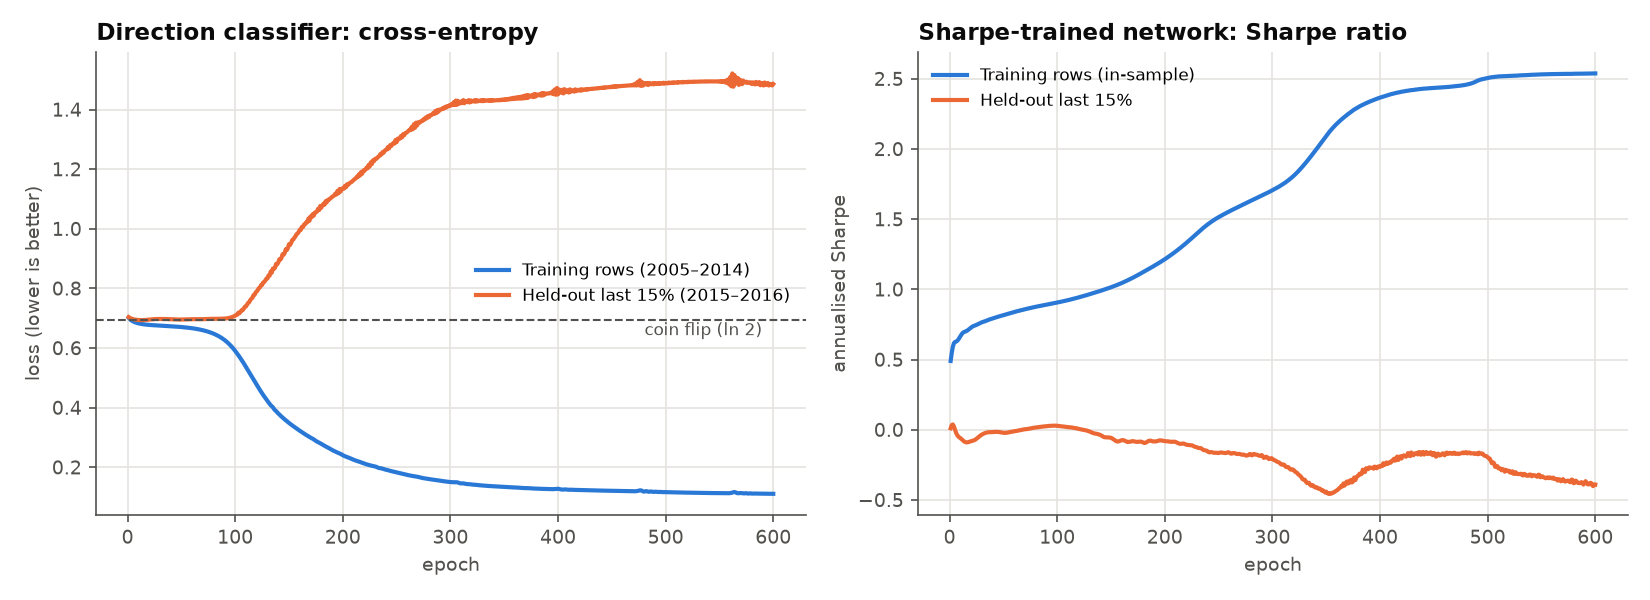

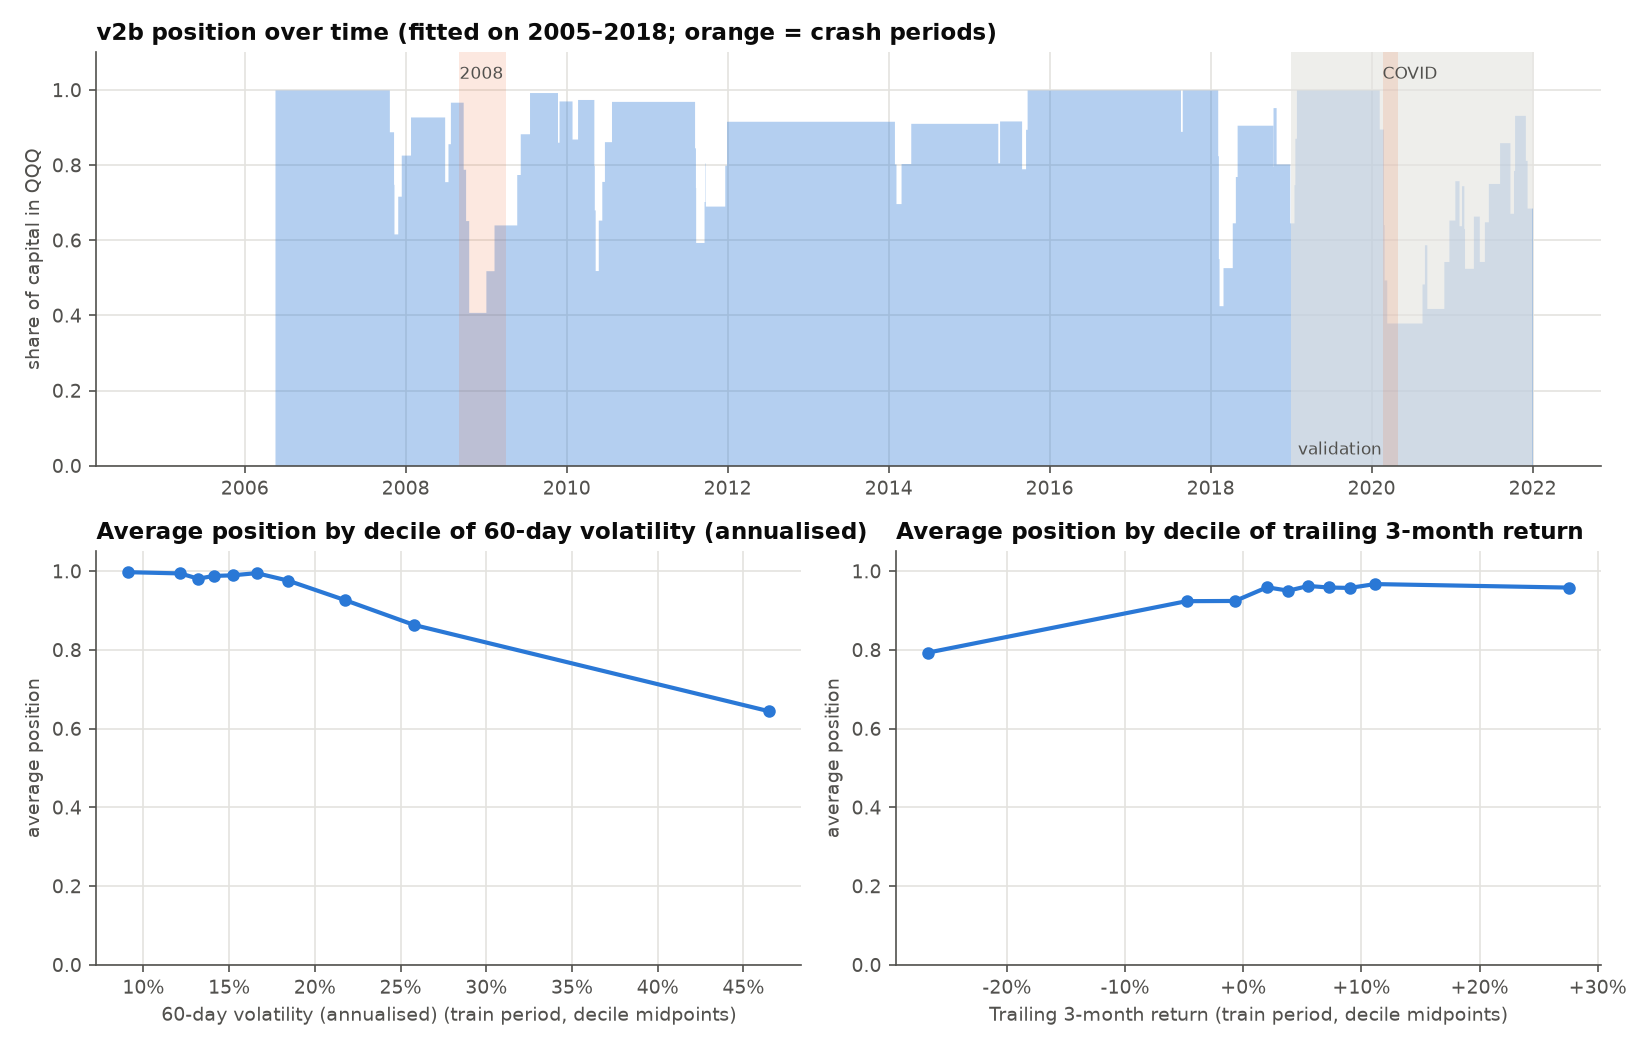

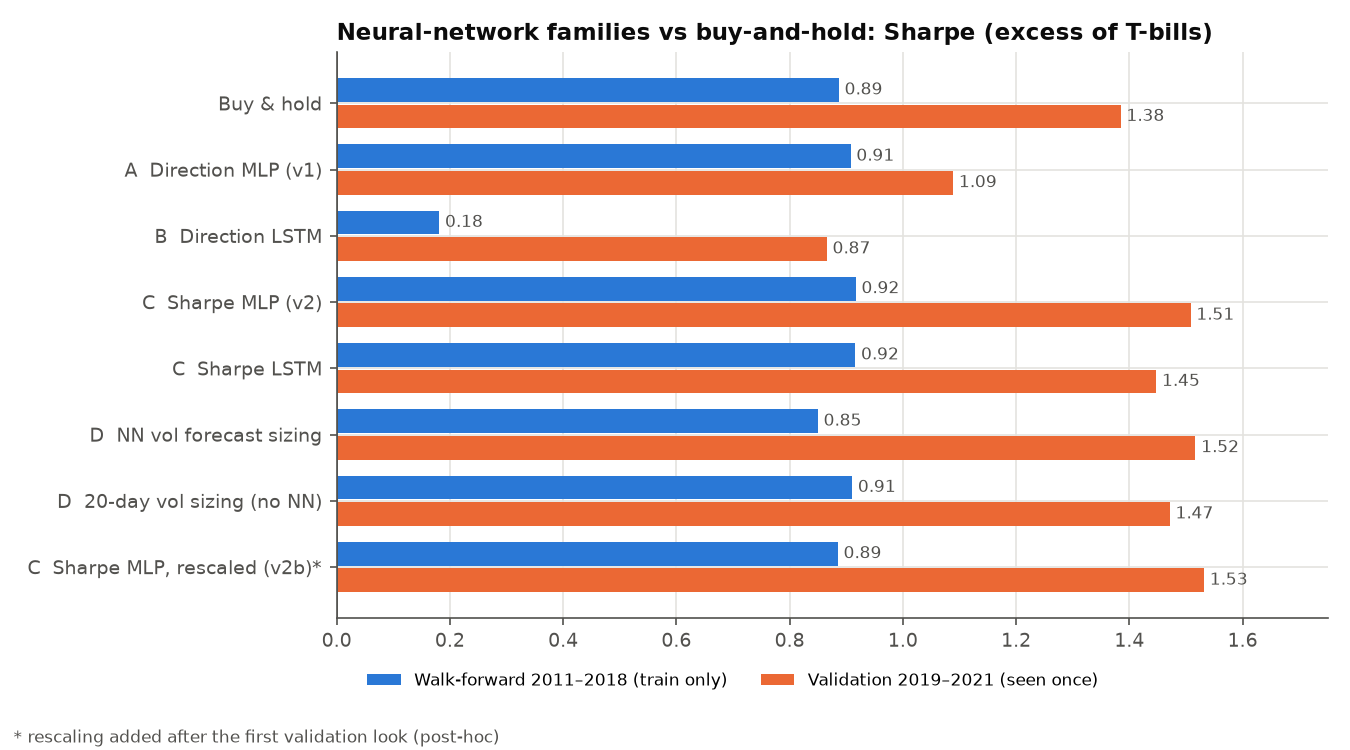

In [9]:
for f in ("overfitting_curves", "what_it_learned", "family_comparison"):
    display(Image(filename=f"figures/{f}.png"))